In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"pakistan_tech_jobs_final.csv")

In [3]:
df.isna().sum()

job_id              0
job_title          12
company             0
job_description     0
required_skills     0
city                0
province            0
experience_min      0
experience_max      0
education          36
employment_type     0
work_mode           0
salary_min          0
salary_max          0
posted_date         0
job_category        0
source_website      0
dtype: int64

In [4]:
df.shape

(2143, 17)

In [5]:
df['job_category'].unique()

<ArrowStringArray>
['Data Science / AI / ML',        'Web Development',     'Mobile Development',
   'Software Development',         'Cloud / DevOps',           'QA / Testing',
          'Cybersecurity']
Length: 7, dtype: str

In [6]:
df['job_title'].unique()

<ArrowStringArray>
[      'Senior Full-Stack & AI Engineer',
  'Front end developer, UI/UX Designing',
             'MACHINE LEARNING ENGINNER',
  'Frontend Developer (React + Next.js)',
        'Mobile App Developer (Flutter)',
                'Jr. Frontend Developer',
                         'UIUX designer',
                    'Frontend Developer',
           'Junior Full Stack Developer',
 'Full-Stack Mobile & Backend Developer',
 ...
             'Embedded Systems Engineer',
                  'Blockchain Developer',
                'Database Administrator',
             'Technical Project Manager',
                           'AI Engineer',
                  'System Administrator',
                        'ERP Consultant',
                  'Mobile App Developer',
                 'IT Support Specialist',
                 'Network Administrator']
Length: 160, dtype: str

In [7]:
df.drop('job_description',inplace=True,axis=1)

In [8]:
df.head(5)

,job_id,job_title,company,required_skills,city,province,experience_min,experience_max,education,employment_type,work_mode,salary_min,salary_max,posted_date,job_category,source_website
0,1001,Senior Full-Stack & AI Engineer,Jack Mitchel,"Python, JavaScript, TypeScript, Node.js, React...",Karachi,Sindh,5.0,8.0,Bachelor's,Full-time,Remote,560000.0,840000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
1,1002,"Front end developer, UI/UX Designing",Sharp Mind,"HTML, CSS, Java, UI/UX Design",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,80000.0,110000.0,2026-10-30,Web Development,Bano Qabil Jobs
2,1003,MACHINE LEARNING ENGINNER,MUHAMMAD AFNAN,"Core ML Expertise, Solid Programming (Python, ...",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,60000.0,100000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
3,1004,Frontend Developer (React + Next.js),VertexInvo,"React, Next.js",Karachi,Sindh,2.0,5.0,Bachelor's,Full-time,On-site,50000.0,60000.0,2026-10-30,Web Development,Bano Qabil Jobs
4,1005,Mobile App Developer (Flutter),Mohsin Shiekh,"Python, JavaScript, SQL, Git",Karachi,Sindh,0.0,2.0,Bachelor's,Full-time,Remote,40000.0,59998.0,2026-10-30,Mobile Development,Bano Qabil Jobs


In [9]:
df.describe()#salary min and max have outliers but they would get normalized

,job_id,experience_min,experience_max,salary_min,salary_max
count,2143.000000,2143.000000,2143.000000,2143.000000,2143.000000
mean,2072.000000,2.025198,3.900140,111543.630425,178245.916006
std,618.775134,1.707434,1.997738,54263.215701,85105.481524
min,1001.000000,0.000000,1.000000,15000.000000,25000.000000
25%,1536.500000,1.000000,3.000000,70000.000000,115000.000000
50%,2072.000000,1.000000,3.000000,95000.000000,160000.000000
75%,2607.500000,3.000000,5.000000,140000.000000,222500.000000
max,3143.000000,6.000000,10.000000,560000.000000,840000.000000


In [10]:
df.isna().sum()
df['education']=df['education'].fillna(df['education'].mode()[0])

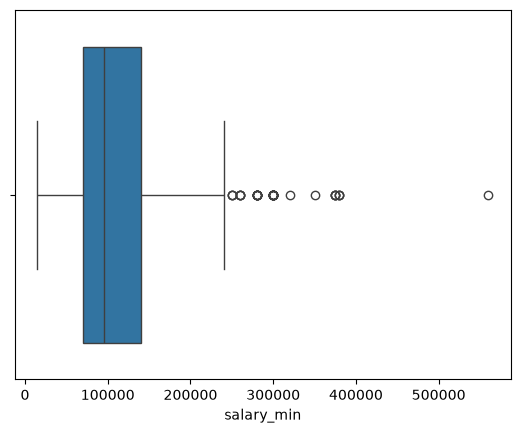

In [11]:
sns.boxplot(data=df,x="salary_min")#the graph is showing us the outliers

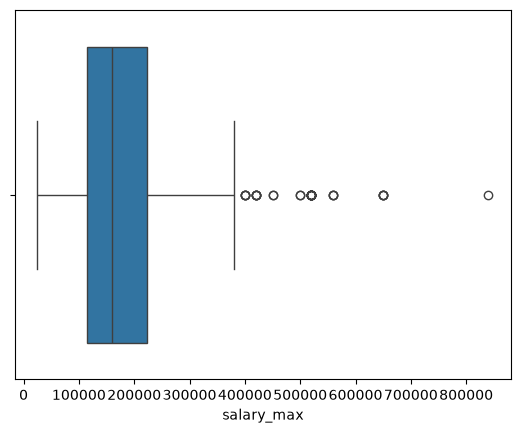

In [12]:
sns.boxplot(data=df,x="salary_max")

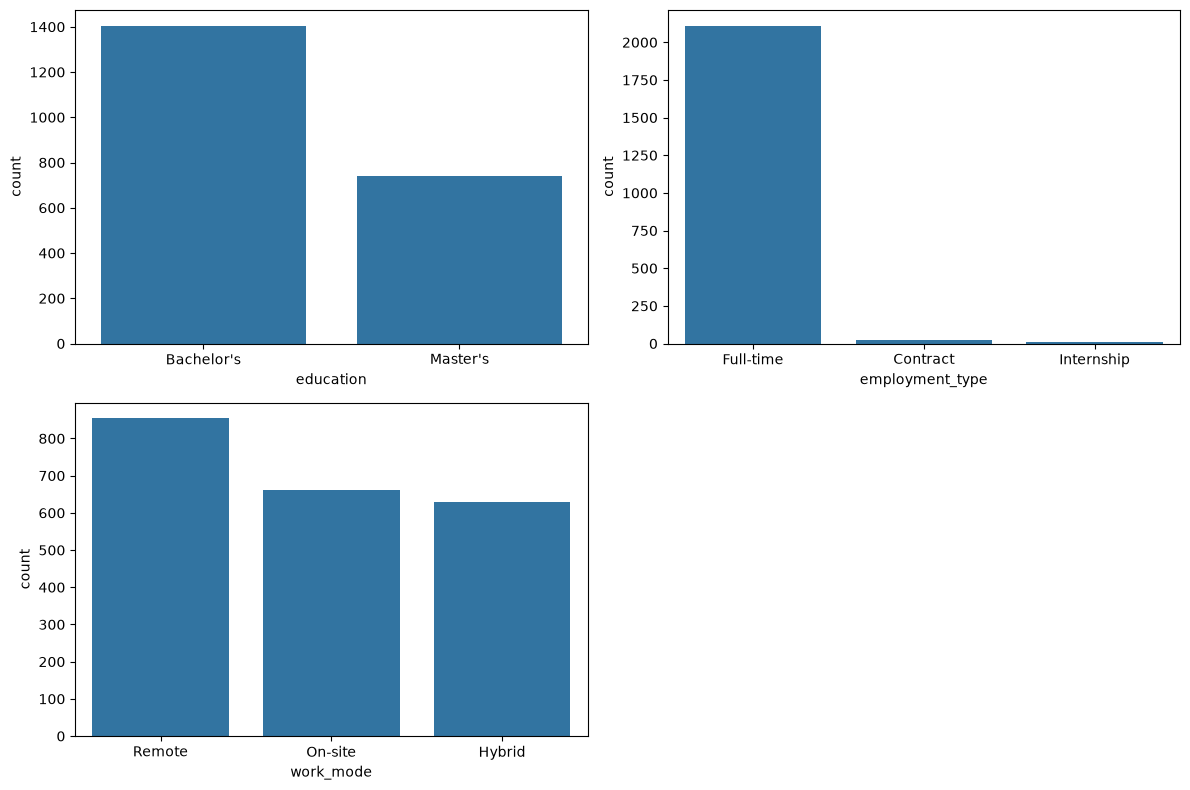

In [13]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
sns.countplot(data=df,x="education",ax=ax[0,0])
sns.countplot(data=df,x="employment_type",ax=ax[0,1])
sns.countplot(data=df,x="work_mode",ax=ax[1,0])
fig.delaxes(ax[1,1])
plt.tight_layout()


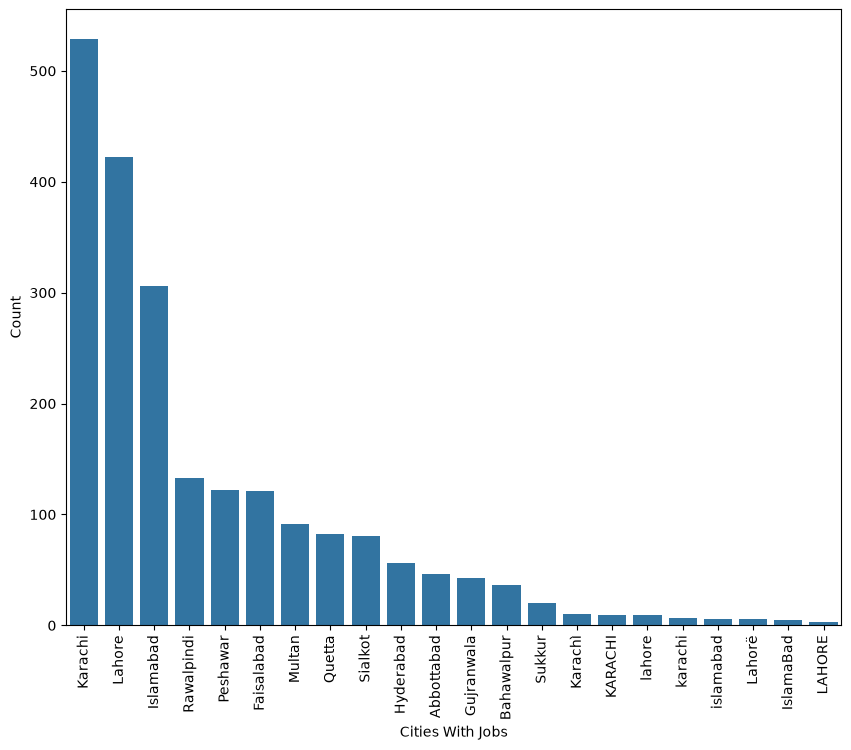

In [14]:
#Which City has Highest Job Posting
fig=plt.figure(figsize=(10,8))
sns.countplot(data=df,x="city",order=df['city'].value_counts().index)
plt.xticks(rotation=90)
plt.xlabel("Cities With Jobs")
plt.ylabel("Count")
plt.show()

In [15]:
df['city']=df['city'].str.lower()
df['city']=df['city'].replace({"karachì":"karachi",'lahorë':'lahore'})
df['city']=df['city'].str.title()

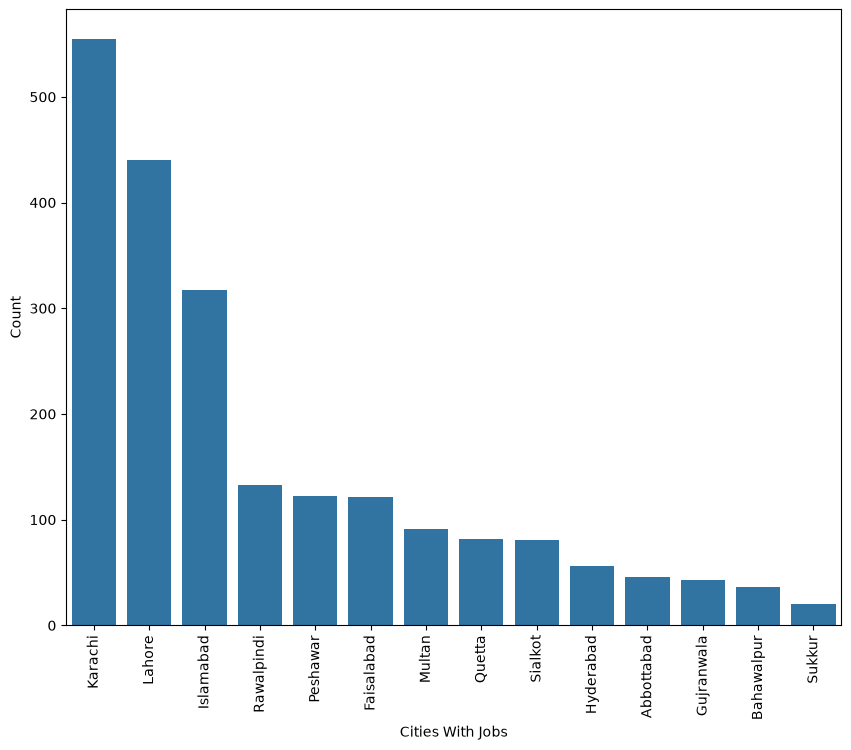

In [16]:
fig=plt.figure(figsize=(10,8))
sns.countplot(data=df,x="city",order=df['city'].value_counts().index)
plt.xticks(rotation=90)
plt.xlabel("Cities With Jobs")
plt.ylabel("Count")
plt.show()

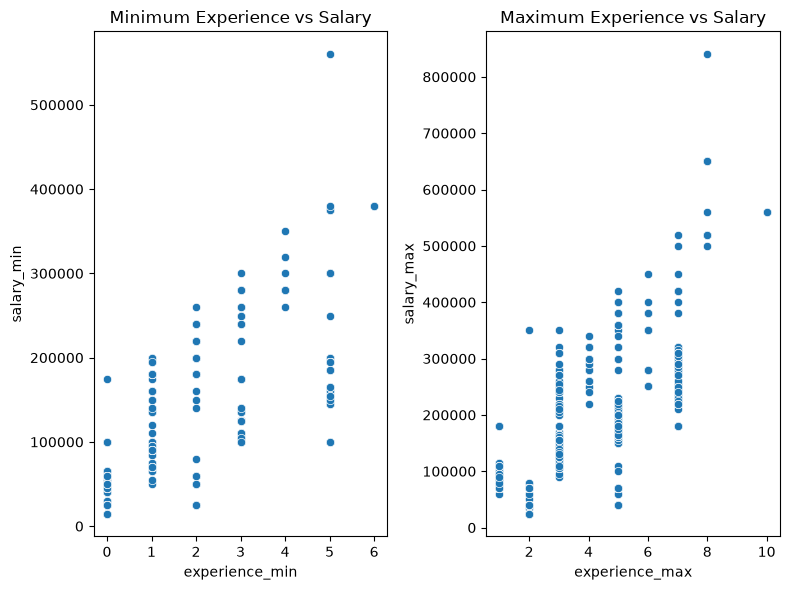

In [17]:
#to show relationship of max experience with max sal and min experience with min sal we use scatter plot
fig,ax=plt.subplots(1,2,figsize=(8,6))
sns.scatterplot(data=df,x="experience_min",y='salary_min',ax=ax[0])
sns.scatterplot(data=df,x="experience_max",y='salary_max',ax=ax[1])
ax[0].set_title("Minimum Experience vs Salary")
ax[1].set_title("Maximum Experience vs Salary")
plt.tight_layout()
plt.show()
#the graphs are showing that higher the experience higher the salary

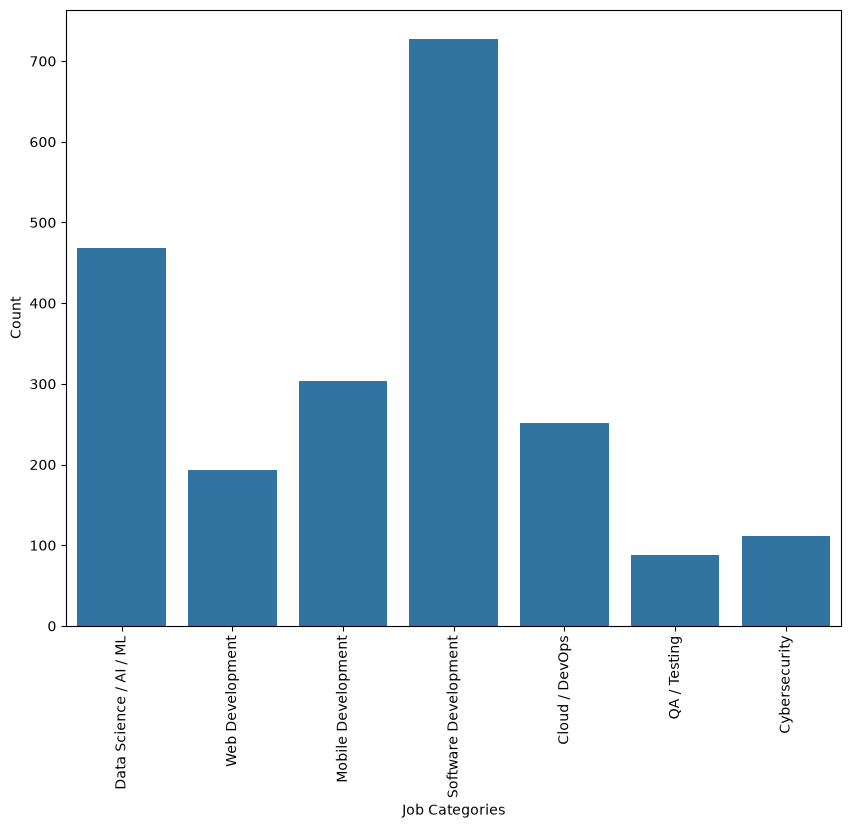

In [18]:
df.columns
#Which Category Jobs has highest posting
fig=plt.figure(figsize=(10,8))
sns.countplot(data=df,x='job_category')
plt.xticks(rotation=90)
plt.xlabel("Job Categories")
plt.ylabel("Count")
plt.show()
#The Software related Jobs are more than any other category

In [19]:
salary_analysis=df.groupby('job_category')[['salary_min','salary_max']].mean().sort_values(by='salary_max', ascending=False)

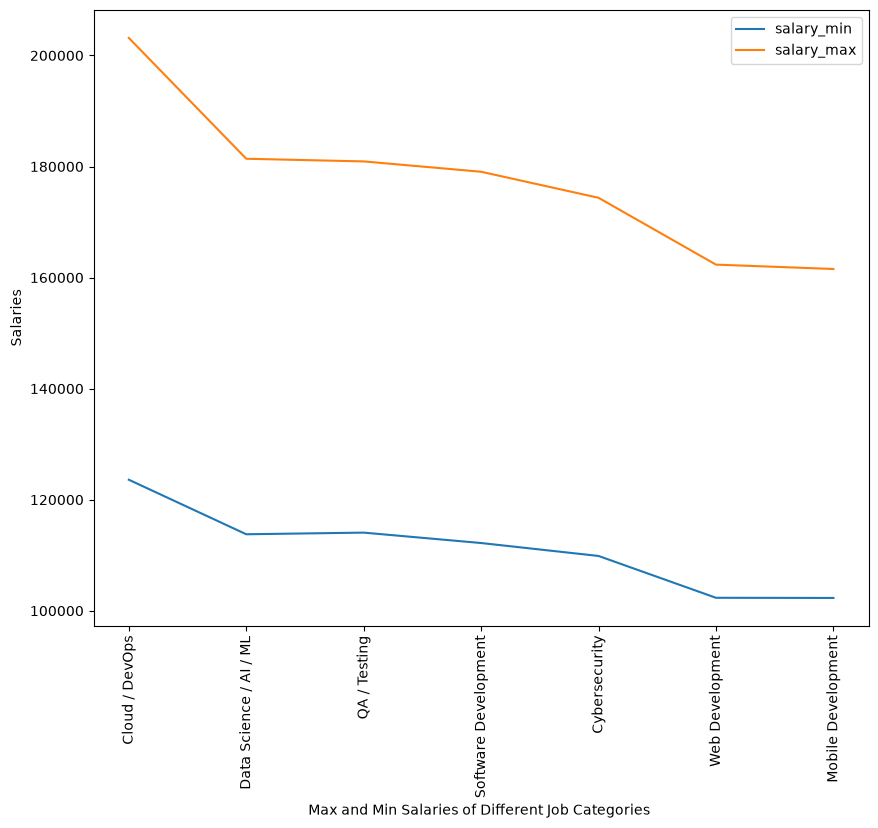

In [20]:
fig, ax = plt.subplots(figsize=(10,8))
salary_analysis.plot(ax=ax)
plt.xticks(rotation=90)
plt.xlabel("Max and Min Salaries of Different Job Categories ")
plt.ylabel("Salaries")
plt.show()
#It is showing that Cloud/Devops Engineers have high min max salaries


In [21]:
exp_analysis=df.groupby('job_category')[['experience_min','experience_max']].mean().sort_values(by='experience_max', ascending=False)
exp_analysis

,experience_min,experience_max
job_category,,
Cloud / DevOps,2.289683,4.285714
QA / Testing,2.386364,4.204545
Data Science / AI / ML,2.059829,3.888889
Software Development,2.013755,3.876204
Mobile Development,1.855263,3.779605
Cybersecurity,1.981982,3.756757
Web Development,1.766839,3.647668


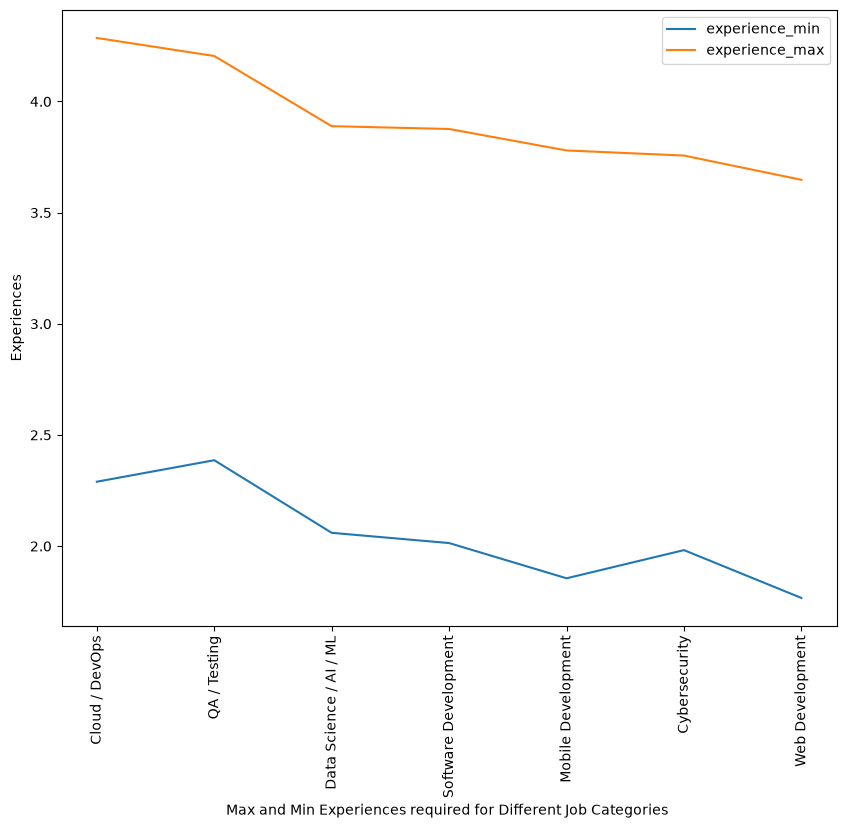

In [22]:
fig, ax = plt.subplots(figsize=(10,8))
exp_analysis.plot(ax=ax)
plt.xticks(rotation=90)
plt.xlabel("Max and Min Experiences required for Different Job Categories ")
plt.ylabel("Experiences")
plt.show()
#Acc to this graph Cloud/Devops related jobs require more experience and give more salaries


In [23]:
df.head()

,job_id,job_title,company,required_skills,city,province,experience_min,experience_max,education,employment_type,work_mode,salary_min,salary_max,posted_date,job_category,source_website
0,1001,Senior Full-Stack & AI Engineer,Jack Mitchel,"Python, JavaScript, TypeScript, Node.js, React...",Karachi,Sindh,5.0,8.0,Bachelor's,Full-time,Remote,560000.0,840000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
1,1002,"Front end developer, UI/UX Designing",Sharp Mind,"HTML, CSS, Java, UI/UX Design",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,80000.0,110000.0,2026-10-30,Web Development,Bano Qabil Jobs
2,1003,MACHINE LEARNING ENGINNER,MUHAMMAD AFNAN,"Core ML Expertise, Solid Programming (Python, ...",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,60000.0,100000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
3,1004,Frontend Developer (React + Next.js),VertexInvo,"React, Next.js",Karachi,Sindh,2.0,5.0,Bachelor's,Full-time,On-site,50000.0,60000.0,2026-10-30,Web Development,Bano Qabil Jobs
4,1005,Mobile App Developer (Flutter),Mohsin Shiekh,"Python, JavaScript, SQL, Git",Karachi,Sindh,0.0,2.0,Bachelor's,Full-time,Remote,40000.0,59998.0,2026-10-30,Mobile Development,Bano Qabil Jobs


In [24]:
#K means to cluster job categories
#Linear to predict min max salries 
#logistic to predict job_title
#KNN to predict five related jobs
#firstly preprocessing
df['job_title']=df['job_title'].fillna(df['job_title'].mode()[0])
df.isna().sum()
df.duplicated().sum()#No Duplicates

np.int64(0)

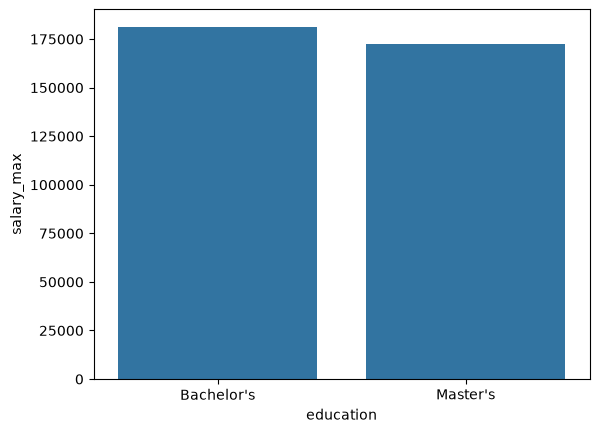

In [25]:
#to show relation between education and sal
sns.barplot(data=df,x="education",y='salary_max',errorbar=None)

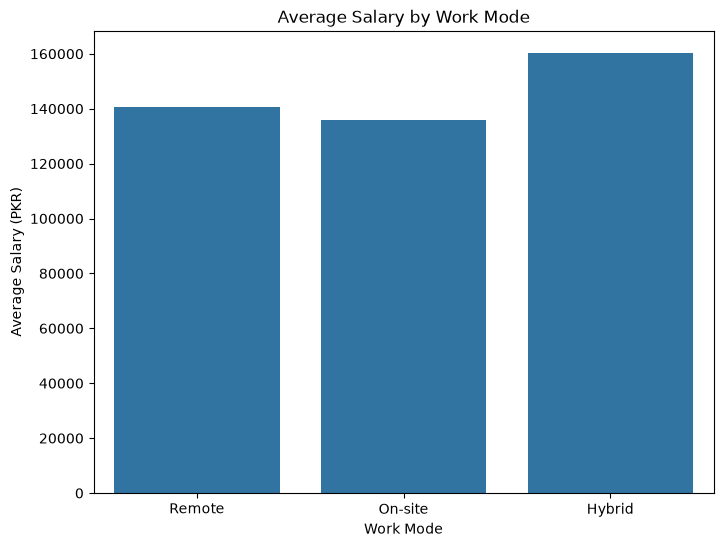

In [26]:
#Average Salary by Work Mode
df['avg_sal']=(df['salary_min']+df['salary_max'])/2
fig=plt.figure(figsize=(8,6))
sns.barplot(data=df,x="work_mode",y="avg_sal",errorbar=None)
plt.title("Average Salary by Work Mode")
plt.xlabel("Work Mode")
plt.ylabel("Average Salary (PKR)")
plt.show()
#Hybrid and Remote jobs pay significantly higher on average than On-site jobs

In [27]:
#Which City pays the highest salary in Pakistan
top_cities=['Karachi','Lahore','Islamabad','Rawalpindi']
city_sal=df[df['city'].isin(top_cities)].groupby('city')['avg_sal'].mean().sort_values(ascending=False).reset_index()
city_sal

,city,avg_sal
0,Islamabad,165432.176656
1,Lahore,161062.500000
2,Karachi,149963.962162
3,Rawalpindi,147048.872180


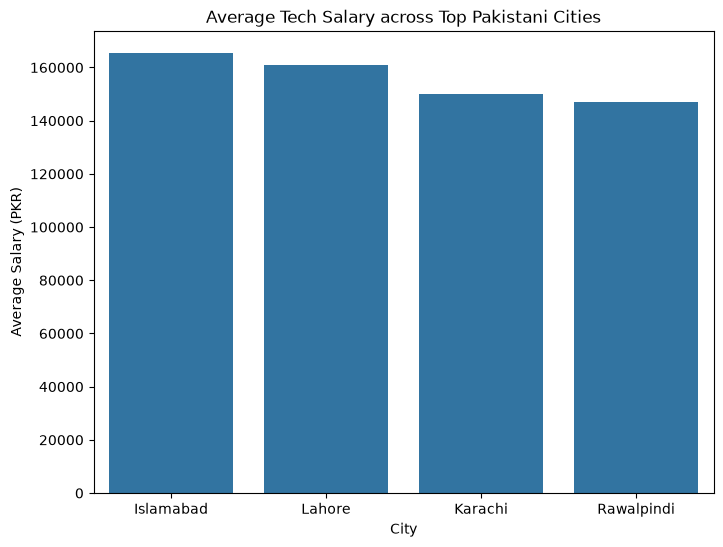

In [28]:
fig=plt.figure(figsize=(8,6))
sns.barplot(data=city_sal,x='city',y='avg_sal')
plt.title("Average Tech Salary across Top Pakistani Cities")
plt.xlabel("City")
plt.ylabel("Average Salary (PKR)")
plt.show()
#Islamabad and Lahore offer the highest tech salaries on average

In [29]:
#Extracting and counting required skills
from collections import Counter
all_skills=[s.strip().lower() for sub in df['required_skills'].dropna().str.split(',') for s in sub if s.strip()]
skill_counts=pd.DataFrame(Counter(all_skills).most_common(15),columns=['Skill','Count'])
skill_counts

,Skill,Count
0,git,371
1,python,344
2,docker,331
3,react,320
4,ci/cd,315
5,aws,308
6,elasticsearch,287
7,sql,286
8,linux,286
9,azure,285


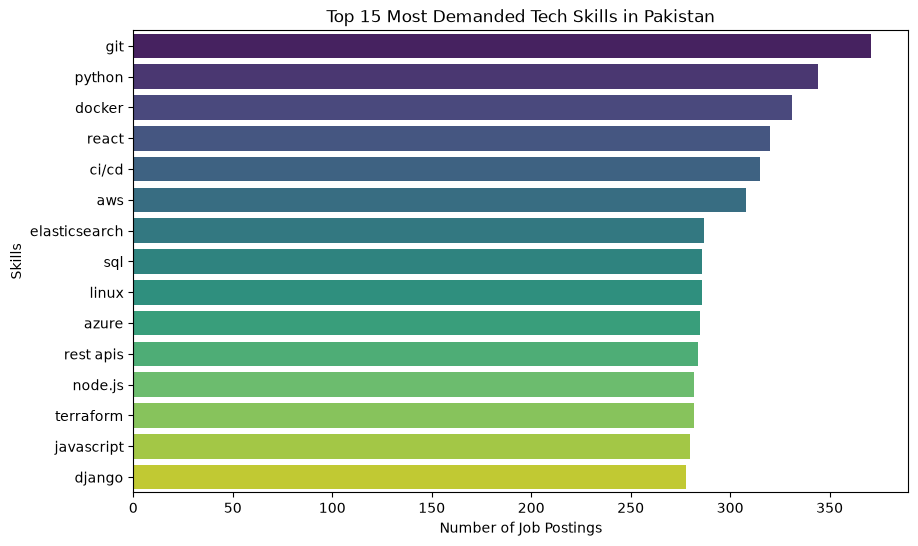

In [30]:
#Top 15 Most Demanded Tech Skills
fig=plt.figure(figsize=(10,6))
sns.barplot(data=skill_counts,x='Count',y='Skill',palette='viridis')
plt.title("Top 15 Most Demanded Tech Skills in Pakistan")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skills")
plt.show()
#Git, Python, Docker, React, and CI/CD are the most demanded skills

In [31]:
#Top Paying Skills in Pakistan
skills_df = df[['required_skills', 'avg_sal']].dropna().copy()
skills_df['skill'] = skills_df['required_skills'].str.lower().str.split(',')
skills_df = skills_df.explode('skill')
skills_df['skill'] = skills_df['skill'].str.strip()

#Group by skill to find average salary
skill_stats = skills_df.groupby('skill')['avg_sal'].agg(['mean', 'count'])

#Filter skills with at least 50 job postings and get top 10
top_paying_skills = skill_stats[skill_stats['count'] >= 50].sort_values(by='mean', ascending=False).head(10).reset_index()
top_paying_skills.rename(columns={'skill': 'Skill', 'mean': 'Avg_Salary'}, inplace=True)
top_paying_skills


,Skill,Avg_Salary,count
0,cloud,248263.636364,55
1,python,179962.206395,344
2,aws,167029.220779,308
3,ci/cd,163657.142857,315
4,react,163562.500000,320
5,git,161373.312668,371
6,sql,160900.346154,286
7,docker,160542.296073,331
8,django,159892.086331,278
9,linux,151125.874126,286


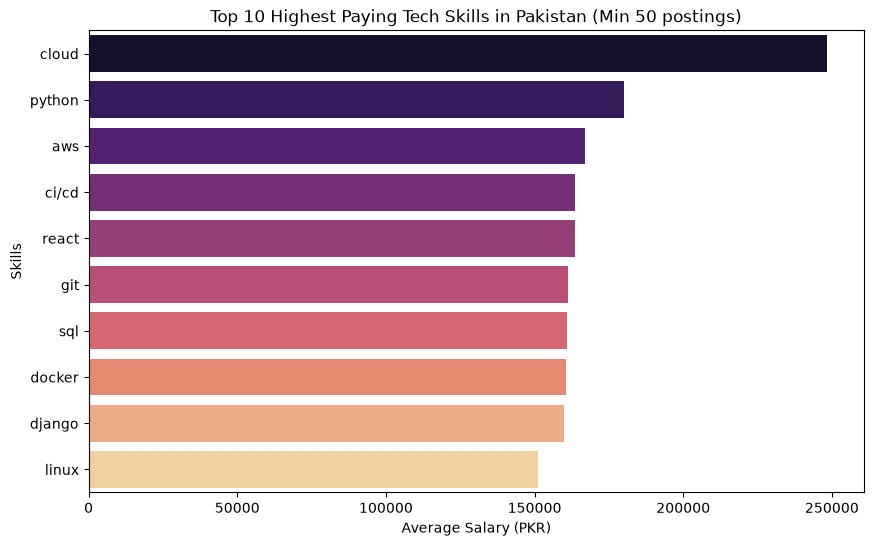

In [32]:
fig=plt.figure(figsize=(10,6))
sns.barplot(data=top_paying_skills,x='Avg_Salary',y='Skill',palette='magma')
plt.title("Top 10 Highest Paying Tech Skills in Pakistan (Min 50 postings)")
plt.xlabel("Average Salary (PKR)")
plt.ylabel("Skills")
plt.show()
#Cloud, Python, AWS, and CI/CD command the highest average compensation

In [33]:
#Top 10 Tech Companies with Most Job Openings
top_companies=df['company'].value_counts().head(10).reset_index()
top_companies.columns=['Company','Job_Postings']
top_companies

,Company,Job_Postings
0,10Pearls,114
1,Devsinc,112
2,Creative Chaos,105
3,Hazen Technologies,100
4,Arbisoft,97
5,Contour Software,97
6,Techlogix,88
7,NetSol Technologies,87
8,Elixir Technologies,87
9,KalSoft,86


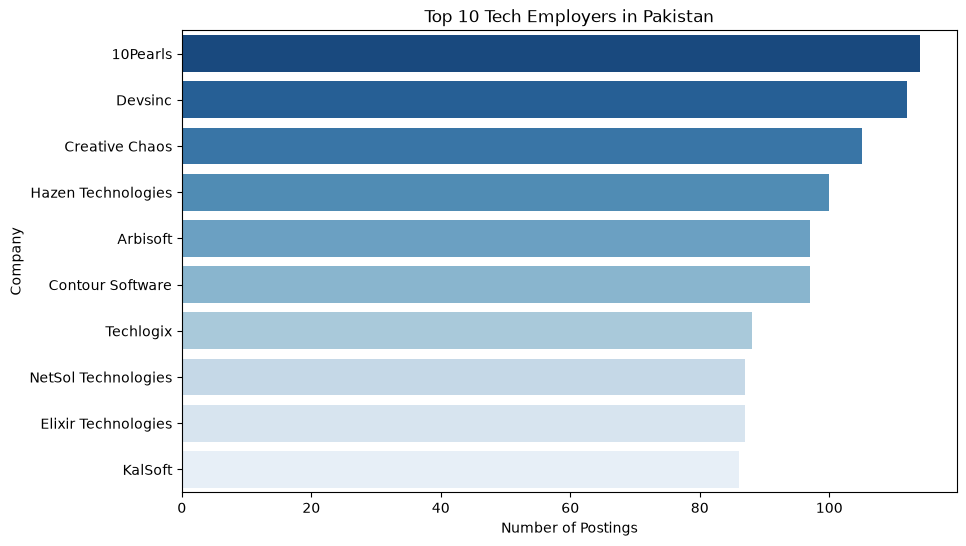

In [34]:
fig=plt.figure(figsize=(10,6))
sns.barplot(data=top_companies,x='Job_Postings',y='Company',palette='Blues_r')
plt.title("Top 10 Tech Employers in Pakistan")
plt.xlabel("Number of Postings")
plt.ylabel("Company")
plt.show()
#10Pearls, Devsinc, Creative Chaos, and Hazen Technologies are the largest tech recruiters

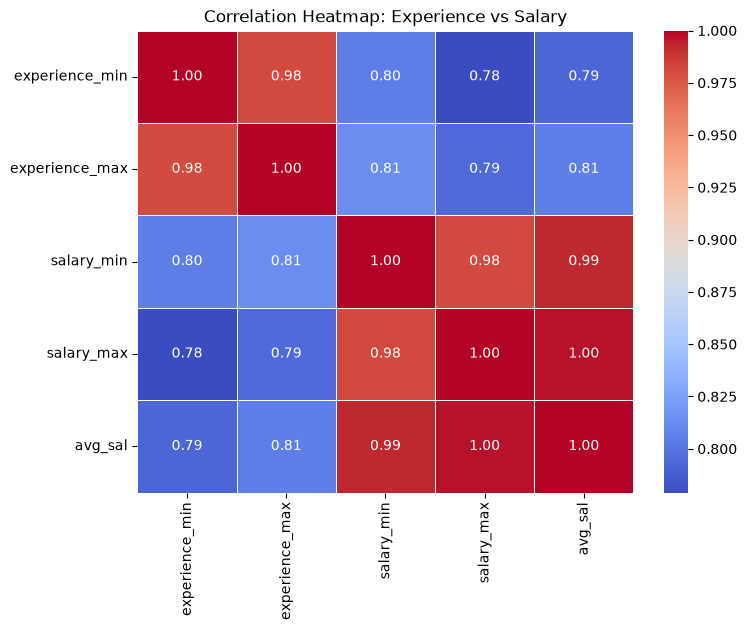

In [35]:
#Correlation Heatmap
numeric_cols=['experience_min','experience_max','salary_min','salary_max','avg_sal']
corr_matrix=df[numeric_cols].corr()

fig=plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt=".2f",linewidths=0.5)
plt.title("Correlation Heatmap: Experience vs Salary")
plt.show()
#High correlation (0.70+) between experience and salary confirms strong predictive relationship

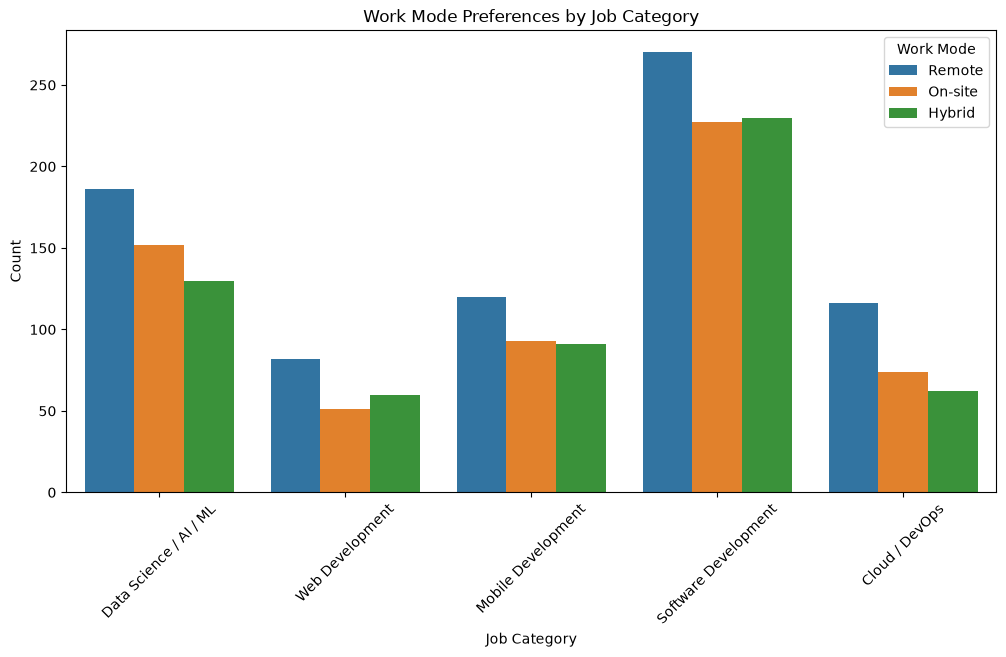

In [ ]:
#Work Mode Distribution across Top Job Categories
top_cats=df['job_category'].value_counts().head(5).index
cat_mode_df=df[df['job_category'].isin(top_cats)]
fig=plt.figure(figsize=(12,6))
sns.countplot(data=cat_mode_df,x='job_category',hue='work_mode')
plt.xticks(rotation=45)
plt.title("Work Mode Preferences by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Count")
plt.legend(title="Work Mode")
plt.show()
#Software Development offers the highest proportion of Hybrid and Remote roles